# **Project Name**    - Ola Ride Insights

##### **Project Type**    - EDA
##### **Contribution**    - Individual
##### **Member -** Adarsh Shrikant Tiwari

# **Project Summary -**

This project analyses one month (1-31 July 2024) of OLA ride-booking data from Bengaluru: **103,024 bookings** across **7 vehicle types**, **50 pickup locations** and **~94.5k unique customers**. Each row is one booking with its status (Success, Canceled by Customer, Canceled by Driver, Driver Not Found), vehicle type, pickup and drop location, vehicle and customer turnaround times (V_TAT / C_TAT), cancellation reasons, incomplete-ride flags, booking value, payment method, ride distance and both driver and customer ratings.

**Data understanding & cleaning.** The raw file has three sheets; only `July` contains booking data (the other two are scratch pivots). There are no duplicate rows or duplicate Booking IDs. Missing values look large (up to 96% in some columns) but they are *structural*: every non-successful booking has no TAT, payment method, ratings or incomplete flag because no ride happened. Text columns were filled with an explicit "Not Applicable" label, while numeric columns (ratings, TAT) were left as nulls so averages are not dragged towards zero. The `Date` column already holds the full timestamp, so the separate `Time` column was dropped after verifying it matched 100%. New features were derived for analysis: day, weekday, weekend flag, hour, time slot, a final `Ride_Outcome` (Completed / Incomplete / cancelled), success and cancel flags, `Revenue` (booking value counted only for successful rides), distance bands and fare per km.

**Key findings.**
* Only **62.1%** of bookings succeed. Drivers cancel **17.9%** of bookings, almost twice as often as customers (**10.2%**), and another **9.8%** fail because no driver was found. That is ~39k lost rides and roughly **₹2.15 Cr** of quoted value in one month.
* The leading driver-side reason is *Personal & Car related issue* (6,542 rides). On the customer side the top two reasons, *Driver not moving towards pickup* (3,175) and *Driver asked to cancel* (2,670), are also driver behaviour problems. Driver behaviour is the biggest lever on fulfilment.
* Demand is very even through the day and across the month (~3,300 bookings/day, ~4,300 per hour). Monday-Wednesday look higher only because July 2024 had five of each; per-day averages are flat.
* Successful rides generated **₹3.51 Cr**. **Cash still dominates (55%)**, with UPI at 40%; cards are under 5%.
* Six vehicle types average ~25 km per successful ride, while **Auto averages just 10 km**, which is consistent with shorter intra-city hops.
* Driver and customer ratings both average **~4.0** and are spread almost uniformly between 3 and 5, with no vehicle type standing out.
* Booking value has **no correlation with distance** (r ≈ 0). Pricing is not distance-driven in this data, and the top 1% of rides cost more than ₹640/km against a ₹20/km median. These are flagged as pricing or fraud anomalies.

**Deliverables.** Alongside this notebook the project includes a cleaned dataset, a MySQL/SQLite SQL script answering the 10 business questions plus 10 extra insight queries, a 5-page Power BI dashboard (Overall, Vehicle Type, Revenue, Cancellation, Ratings) and a Streamlit app that runs the SQL queries interactively with filters and embeds the Power BI report.

**Recommendations.** Reduce driver-side cancellations with penalties and incentives and better pickup ETA tracking, add supply in "Driver Not Found" pockets, push digital payments with UPI cashback, audit high fare-per-km rides, and introduce a richer rating system that drives coaching for low-rated drivers.

# **GitHub Link -**

https://github.com/adarsh-tiwari29/ola-ride-insights

# **Problem Statement**


OLA generates large volumes of booking data covering ride status, driver availability, fares, payments and ratings, but turning it into decisions is hard. The goal of this project is to clean and process one month of OLA booking data, run exploratory analysis, answer key business questions with SQL, and present the results through an interactive Power BI dashboard and a Streamlit web app, so that operations, marketing and pricing teams can act on them.

#### **Define Your Business Objective?**

* **Improve fulfilment**: understand why ~38% of bookings do not turn into rides and which levers (driver behaviour, supply) matter most.
* **Optimise driver allocation**: find peak demand hours and days.
* **Understand customers and payments**: payment mix, repeat customers and high-value customers for targeted marketing.
* **Check pricing**: how fares relate to distance and vehicle type, and spot anomalous or potentially fraudulent bookings.
* **Track service quality**: driver and customer ratings by vehicle type.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

# OLA brand-ish colours used across charts
OLA_GREEN, OLA_DARK, OLA_GREY = "#8CC63F", "#1F2A2E", "#9AA5A9"
STATUS_COLORS = {"Success": OLA_GREEN, "Canceled by Driver": "#E4572E",
                 "Canceled by Customer": "#F3A712", "Driver Not Found": OLA_GREY}

### Dataset Loading

In [2]:
# Load Dataset
# The notebook works from the project root, from /notebooks, or on Colab (upload the xlsx next to it).
CANDIDATES = [Path("../data/raw/OLA_DataSet.xlsx"), Path("data/raw/OLA_DataSet.xlsx"), Path("OLA_DataSet.xlsx")]

def load_raw():
    for p in CANDIDATES:
        if p.exists():
            # Only the 'July' sheet holds booking data; Sheet1/Sheet2 are scratch pivots
            return pd.read_excel(p, sheet_name="July"), p
    raise FileNotFoundError("OLA_DataSet.xlsx not found - place it in data/raw/ or next to this notebook.")

try:
    raw_df, DATA_PATH = load_raw()
    print(f"Loaded {DATA_PATH}")
except Exception as e:
    raise SystemExit(f"Could not load dataset: {e}")

df = raw_df.copy()

Loaded ../data/raw/OLA_DataSet.xlsx


### Dataset First View

In [3]:
# Dataset First Look
df.head()

,Date,Time,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating,Vehicle Images
0,2024-07-26 14:00:00,14:00:00,CNR7153255142,Canceled by Driver,CID713523,Prime Sedan,Tumkur Road,RT Nagar,NaN,NaN,NaN,Personal & Car related issue,NaN,NaN,444,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/14183/1...
1,2024-07-25 22:20:00,22:20:00,CNR2940424040,Success,CID225428,Bike,Magadi Road,Varthur,203.0,30.0,NaN,NaN,No,NaN,158,Cash,13,4.1,4.0,https://cdn-icons-png.flaticon.com/128/9983/99...
2,2024-07-30 19:59:00,19:59:00,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,238.0,130.0,NaN,NaN,No,NaN,386,UPI,40,4.2,4.8,https://cdn-icons-png.flaticon.com/128/9983/99...
3,2024-07-22 03:15:00,03:15:00,CNR2395710036,Canceled by Customer,CID581320,eBike,HSR Layout,Vijayanagar,NaN,NaN,Driver is not moving towards pickup location,NaN,NaN,NaN,384,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/6839/68...
4,2024-07-02 09:02:00,09:02:00,CNR1797421769,Success,CID939555,Mini,Rajajinagar,Chamarajpet,252.0,80.0,NaN,NaN,No,NaN,822,Credit Card,45,4.0,3.0,https://cdn-icons-png.flaticon.com/128/3202/32...


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")

Rows: 103,024  |  Columns: 20


### Dataset Information

In [5]:
# Dataset Info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 103024 entries, 0 to 103023
Data columns (total 20 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   Date                        103024 non-null  datetime64[us]
 1   Time                        103024 non-null  object        
 2   Booking_ID                  103024 non-null  str           
 3   Booking_Status              103024 non-null  str           
 4   Customer_ID                 103024 non-null  str           
 5   Vehicle_Type                103024 non-null  str           
 6   Pickup_Location             103024 non-null  str           
 7   Drop_Location               103024 non-null  str           
 8   V_TAT                       63967 non-null   float64       
 9   C_TAT                       63967 non-null   float64       
 10  Canceled_Rides_by_Customer  10499 non-null   str           
 11  Canceled_Rides_by_Driver    18434 non-null   str  

#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print("Fully duplicated rows :", df.duplicated().sum())
print("Duplicate Booking_IDs :", df["Booking_ID"].duplicated().sum())

Fully duplicated rows : 0


Duplicate Booking_IDs : 0


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
missing = df.isna().sum().to_frame("Missing").assign(Pct=lambda x: (x.Missing / len(df) * 100).round(2))
missing[missing.Missing > 0].sort_values("Missing", ascending=False)

,Missing,Pct
Incomplete_Rides_Reason,99098,96.19
Canceled_Rides_by_Customer,92525,89.81
Canceled_Rides_by_Driver,84590,82.11
V_TAT,39057,37.91
C_TAT,39057,37.91
Incomplete_Rides,39057,37.91
Payment_Method,39057,37.91
Driver_Ratings,39057,37.91
Customer_Rating,39057,37.91


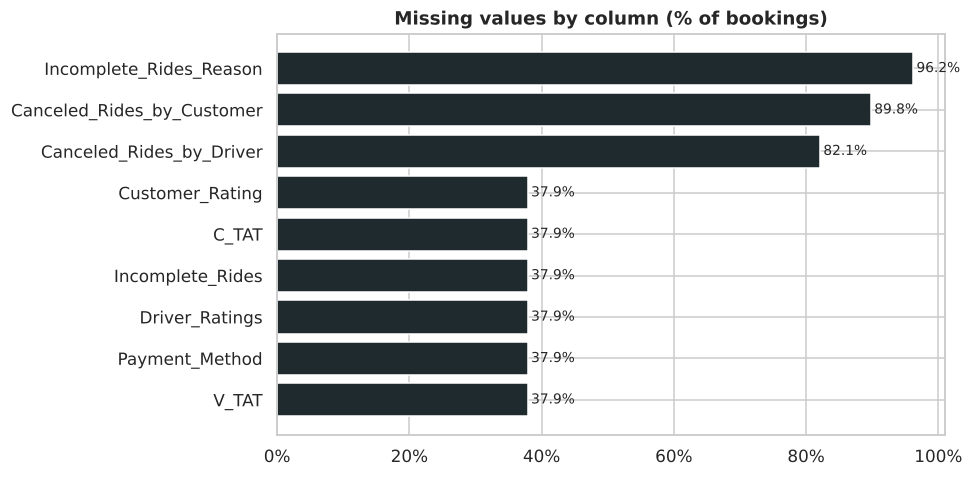

Rows without Payment_Method == non-success rows: True


In [8]:
# Visualizing the missing values
miss_pct = df.isna().mean().mul(100).sort_values()
miss_pct = miss_pct[miss_pct > 0]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(miss_pct.index, miss_pct.values, color=OLA_DARK)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Missing values by column (% of bookings)")
for i, v in enumerate(miss_pct.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
plt.tight_layout(); plt.show()

# Missing values are structural: check they line up exactly with non-successful bookings
non_success = df["Booking_Status"] != "Success"
print("Rows without Payment_Method == non-success rows:", (df["Payment_Method"].isna() == non_success).all())

### What did you know about your dataset?

* The dataset has **103,024 bookings × 20 columns** for **1-31 July 2024** (Bengaluru locations).
* Only the `July` sheet is relevant; `Sheet1` and `Sheet2` are scratch pivot tables.
* **No duplicate rows or Booking IDs.**
* Missing values are **structural, not random**: the 39,057 non-successful bookings have no V_TAT, C_TAT, payment method, ratings or incomplete flag because the ride never happened. Cancellation-reason columns are filled only for the matching cancellation status, and `Incomplete_Rides_Reason` only for incomplete rides.
* `Date` already includes the time, so `Time` is redundant. `Vehicle Images` is just an icon URL per vehicle type (useful for the dashboard, not for analysis).
* Cancelled bookings still carry a `Booking_Value` (the quoted fare) but a `Ride_Distance` of 0, so revenue and distance analysis must use successful rides only.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
list(df.columns)

['Date',
 'Time',
 'Booking_ID',
 'Booking_Status',
 'Customer_ID',
 'Vehicle_Type',
 'Pickup_Location',
 'Drop_Location',
 'V_TAT',
 'C_TAT',
 'Canceled_Rides_by_Customer',
 'Canceled_Rides_by_Driver',
 'Incomplete_Rides',
 'Incomplete_Rides_Reason',
 'Booking_Value',
 'Payment_Method',
 'Ride_Distance',
 'Driver_Ratings',
 'Customer_Rating',
 'Vehicle Images']

In [10]:
# Dataset Describe
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Date,103024,NaN,NaN,NaN,2024-07-16 11:31:38.879678,2024-07-01 00:00:00,2024-07-08 18:41:00,2024-07-16 11:23:00,2024-07-24 05:18:00,2024-07-31 23:58:00,NaN
Time,103024,1440,00:53:00,101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Booking_ID,103024,103024,CNR7153255142,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Booking_Status,103024,4,Success,63967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,103024,94544,CID954071,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle_Type,103024,7,Prime Sedan,14877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pickup_Location,103024,50,Banashankari,2201,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Drop_Location,103024,50,Peenya,2159,NaN,NaN,NaN,NaN,NaN,NaN,NaN
V_TAT,63967.0,NaN,NaN,NaN,170.876952,35.0,98.0,168.0,238.0,308.0,80.80364
C_TAT,63967.0,NaN,NaN,NaN,84.873372,25.0,55.0,85.0,115.0,145.0,36.0051


### Variables Description

| Column | Description |
|---|---|
| Date | Booking timestamp (date + time) |
| Time | Booking time of day (duplicate of the time in Date) |
| Booking_ID | Unique booking id |
| Booking_Status | Success / Canceled by Customer / Canceled by Driver / Driver Not Found |
| Customer_ID | Customer id |
| Vehicle_Type | Prime Sedan, Prime SUV, Prime Plus, Mini, Auto, Bike, eBike |
| Pickup_Location / Drop_Location | Bengaluru area names (50 unique) |
| V_TAT | Vehicle turnaround time: time taken by the vehicle to reach the customer |
| C_TAT | Customer turnaround time: time taken by the customer to board |
| Canceled_Rides_by_Customer | Reason when the customer cancelled |
| Canceled_Rides_by_Driver | Reason when the driver cancelled |
| Incomplete_Rides | Yes/No: did a successful booking end before the destination |
| Incomplete_Rides_Reason | Customer Demand / Vehicle Breakdown / Other Issue |
| Booking_Value | Fare amount (₹) |
| Payment_Method | Cash, UPI, Credit Card, Debit Card |
| Ride_Distance | Distance travelled (km), 0 for non-successful bookings |
| Driver_Ratings | Rating given to the driver (3-5) |
| Customer_Rating | Rating given to the customer (3-5) |
| Vehicle Images | Icon URL for the vehicle type |

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
uniq = df.nunique().to_frame("Unique_Values")
uniq["Sample"] = [df[c].dropna().unique()[:4].tolist() for c in df.columns]
uniq

,Unique_Values,Sample
Date,40214,"[2024-07-26 14:00:00, 2024-07-25 22:20:00, 202..."
Time,1440,"[14:00:00, 22:20:00, 19:59:00, 03:15:00]"
Booking_ID,103024,"[CNR7153255142, CNR2940424040, CNR2982357879, ..."
Booking_Status,4,"[Canceled by Driver, Success, Canceled by Cust..."
Customer_ID,94544,"[CID713523, CID225428, CID270156, CID581320]"
Vehicle_Type,7,"[Prime Sedan, Bike, Prime SUV, eBike]"
Pickup_Location,50,"[Tumkur Road, Magadi Road, Sahakar Nagar, HSR ..."
Drop_Location,50,"[RT Nagar, Varthur, Vijayanagar, Chamarajpet]"
V_TAT,40,"[203.0, 238.0, 252.0, 231.0]"
C_TAT,25,"[30.0, 130.0, 80.0, 90.0]"


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Write your code to make your dataset analysis ready.
# Same logic as src/clean.py (the pipeline used for SQL / Power BI / Streamlit).
NA_LABEL = "Not Applicable"

def clean(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # 1. Standardise column names (no spaces) and trim text columns
    df.columns = [c.strip().replace(" ", "_") for c in df.columns]
    obj_cols = df.select_dtypes(include=["object", "string"]).columns
    for c in obj_cols:
        if c != "Time":
            df[c] = df[c].astype("string").str.strip()

    # 2. Drop exact duplicates / duplicate booking ids (none expected, kept as a safeguard)
    df = df.drop_duplicates().drop_duplicates(subset="Booking_ID", keep="first")

    # 3. Date & time: `Date` already holds the full timestamp, `Time` is a duplicate time-of-day
    df["Booking_Datetime"] = pd.to_datetime(df["Date"])
    df["Booking_Date"] = df["Booking_Datetime"].dt.date
    df["Booking_Time"] = df["Booking_Datetime"].dt.strftime("%H:%M:%S")
    df = df.drop(columns=["Date", "Time"])

    # 4. Missing values - they are structural, not random:
    #    every non-Success booking has no TAT, payment, ratings or Incomplete flag.
    #    Text columns -> explicit label; numeric columns stay NULL so averages are not distorted.
    df["Canceled_Rides_by_Customer"] = df["Canceled_Rides_by_Customer"].fillna(NA_LABEL)
    df["Canceled_Rides_by_Driver"] = df["Canceled_Rides_by_Driver"].fillna(NA_LABEL)
    df["Incomplete_Rides"] = df["Incomplete_Rides"].fillna(NA_LABEL)
    df["Incomplete_Rides_Reason"] = df["Incomplete_Rides_Reason"].fillna(NA_LABEL)
    df["Payment_Method"] = df["Payment_Method"].fillna(NA_LABEL)

    # 5. Types
    for c in ["V_TAT", "C_TAT", "Driver_Ratings", "Customer_Rating"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df["Booking_Value"] = pd.to_numeric(df["Booking_Value"], errors="coerce").astype("Int64")
    df["Ride_Distance"] = pd.to_numeric(df["Ride_Distance"], errors="coerce").astype("Int64")

    # 6. Derived features
    dt = df["Booking_Datetime"]
    df["Day"] = dt.dt.day
    df["Day_Name"] = dt.dt.day_name()
    df["Weekday_Num"] = dt.dt.dayofweek + 1  # Monday = 1
    df["Is_Weekend"] = np.where(df["Weekday_Num"] >= 6, "Weekend", "Weekday")
    df["Hour"] = dt.dt.hour
    df["Time_Slot"] = pd.cut(
        df["Hour"],
        bins=[-1, 5, 11, 16, 20, 23],
        labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-16)", "Evening (17-20)", "Late Evening (21-23)"],
    ).astype("string")

    # Final ride outcome: splits Success into Completed vs Incomplete
    df["Ride_Outcome"] = np.select(
        [
            (df["Booking_Status"] == "Success") & (df["Incomplete_Rides"] == "Yes"),
            df["Booking_Status"] == "Success",
        ],
        ["Incomplete", "Completed"],
        default=df["Booking_Status"],
    )
    df["Is_Success"] = (df["Booking_Status"] == "Success").astype(int)
    df["Is_Canceled"] = df["Booking_Status"].isin(["Canceled by Customer", "Canceled by Driver"]).astype(int)

    # Revenue only counts for successful bookings (cancelled rows still carry a quoted fare)
    df["Revenue"] = np.where(df["Is_Success"] == 1, df["Booking_Value"], 0)

    df["Distance_Band"] = pd.cut(
        df["Ride_Distance"].astype(float),
        bins=[-1, 0, 10, 20, 30, 40, 50],
        labels=["0 km (no ride)", "1-10 km", "11-20 km", "21-30 km", "31-40 km", "41-50 km"],
    ).astype("string")

    # Value per km for successful rides (pricing pattern analysis)
    dist = df["Ride_Distance"].astype(float).replace(0, np.nan)
    df["Fare_per_km"] = np.where(df["Is_Success"] == 1, (df["Booking_Value"] / dist).round(2), np.nan)

    order = [
        "Booking_ID", "Booking_Datetime", "Booking_Date", "Booking_Time", "Day", "Day_Name", "Weekday_Num",
        "Is_Weekend", "Hour", "Time_Slot", "Booking_Status", "Ride_Outcome", "Is_Success", "Is_Canceled",
        "Customer_ID", "Vehicle_Type", "Pickup_Location", "Drop_Location", "V_TAT", "C_TAT",
        "Canceled_Rides_by_Customer", "Canceled_Rides_by_Driver", "Incomplete_Rides", "Incomplete_Rides_Reason",
        "Booking_Value", "Revenue", "Payment_Method", "Ride_Distance", "Distance_Band", "Fare_per_km",
        "Driver_Ratings", "Customer_Rating", "Vehicle_Images",
    ]
    return df[order].sort_values("Booking_Datetime").reset_index(drop=True)


df_clean = clean(df)

# Sanity checks
assert len(df_clean) == len(df), "row count changed during cleaning"
assert df_clean["Booking_ID"].is_unique
assert (df_clean["Revenue"][df_clean["Is_Success"] == 0] == 0).all()

# Save the cleaned dataset (used by SQL, Power BI and Streamlit)
try:
    out_dir = DATA_PATH.parent.parent / "processed" if DATA_PATH.parent.name == "raw" else Path(".")
    out_dir.mkdir(parents=True, exist_ok=True)
    df_clean.drop(columns=["Vehicle_Images"]).to_csv(out_dir / "ola_rides_clean.csv", index=False)
    print("Saved:", out_dir / "ola_rides_clean.csv")
except OSError as e:
    print("Could not save cleaned file:", e)

# Handy subsets used below
success = df_clean[df_clean["Is_Success"] == 1]
VEH_ORDER = ["Prime Sedan", "Prime SUV", "Prime Plus", "Mini", "Auto", "Bike", "eBike"]
print(df_clean.shape)
df_clean.head()

Saved: ../data/processed/ola_rides_clean.csv
(103024, 33)


,Booking_ID,Booking_Datetime,Booking_Date,Booking_Time,Day,Day_Name,Weekday_Num,Is_Weekend,Hour,Time_Slot,Booking_Status,Ride_Outcome,Is_Success,Is_Canceled,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Revenue,Payment_Method,Ride_Distance,Distance_Band,Fare_per_km,Driver_Ratings,Customer_Rating,Vehicle_Images
0,CNR4197668379,2024-07-01 00:00:00,2024-07-01,00:00:00,1,Monday,1,Weekday,0,Night (0-5),Success,Completed,1,0,CID451984,Prime Plus,Malleshwaram,BTM Layout,238.0,140.0,Not Applicable,Not Applicable,No,Not Applicable,791,791,Cash,31,31-40 km,25.52,3.1,4.7,https://cdn-icons-png.flaticon.com/128/11409/1...
1,CNR4091573505,2024-07-01 00:00:00,2024-07-01,00:00:00,1,Monday,1,Weekday,0,Night (0-5),Canceled by Driver,Canceled by Driver,0,1,CID742344,eBike,Yeshwanthpur,Devanahalli,NaN,NaN,Not Applicable,Customer was coughing/sick,Not Applicable,Not Applicable,367,0,Not Applicable,0,0 km (no ride),NaN,NaN,NaN,https://cdn-icons-png.flaticon.com/128/6839/68...
2,CNR7037451850,2024-07-01 00:02:00,2024-07-01,00:02:00,1,Monday,1,Weekday,0,Night (0-5),Canceled by Driver,Canceled by Driver,0,1,CID159762,Mini,Padmanabhanagar,Magadi Road,NaN,NaN,Not Applicable,More than permitted people in there,Not Applicable,Not Applicable,1985,0,Not Applicable,0,0 km (no ride),NaN,NaN,NaN,https://cdn-icons-png.flaticon.com/128/3202/32...
3,CNR3610392570,2024-07-01 00:03:00,2024-07-01,00:03:00,1,Monday,1,Weekday,0,Night (0-5),Success,Incomplete,1,0,CID569014,eBike,JP Nagar,Sarjapur Road,196.0,60.0,Not Applicable,Not Applicable,Yes,Customer Demand,120,120,Credit Card,26,21-30 km,4.62,3.1,4.4,https://cdn-icons-png.flaticon.com/128/6839/68...
4,CNR8282131599,2024-07-01 00:04:00,2024-07-01,00:04:00,1,Monday,1,Weekday,0,Night (0-5),Success,Completed,1,0,CID332553,Auto,Langford Town,JP Nagar,259.0,140.0,Not Applicable,Not Applicable,No,Not Applicable,170,170,Cash,5,1-10 km,34.00,4.3,3.5,https://cdn-icons-png.flaticon.com/128/16526/1...


### What all manipulations have you done and insights you found?

**Manipulations**
1. Read only the `July` sheet, standardised column names (`Vehicle Images` → `Vehicle_Images`) and trimmed text.
2. Dropped duplicates as a safeguard (none found).
3. Parsed `Date` into `Booking_Datetime`, `Booking_Date` and `Booking_Time`, and dropped the redundant `Time` column.
4. Missing values: filled cancellation reasons, incomplete flag/reason and payment method with **"Not Applicable"**. Ratings and TAT were **kept as null** because filling with 0 would wrongly pull averages down.
5. Enforced numeric types on fare, distance, TAT and ratings.
6. Derived features: `Day`, `Day_Name`, `Weekday_Num`, `Is_Weekend`, `Hour`, `Time_Slot`, `Ride_Outcome` (Completed / Incomplete / cancellation type), `Is_Success`, `Is_Canceled`, `Revenue` (fare only for successful rides), `Distance_Band` and `Fare_per_km`.

**Insights found while wrangling**
* 63,967 successful rides (62.1%); 3,926 of them (6.1%) ended **incomplete**.
* Cancelled bookings carry ₹1.6 Cr of quoted fares and "Driver Not Found" another ₹0.55 Cr. That is the revenue left on the table.
* Customer IDs are almost unique (86.6k customers booked once and only one booked 5 times), so "top customers by ride count" is a near-tie list.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Booking Status Breakdown

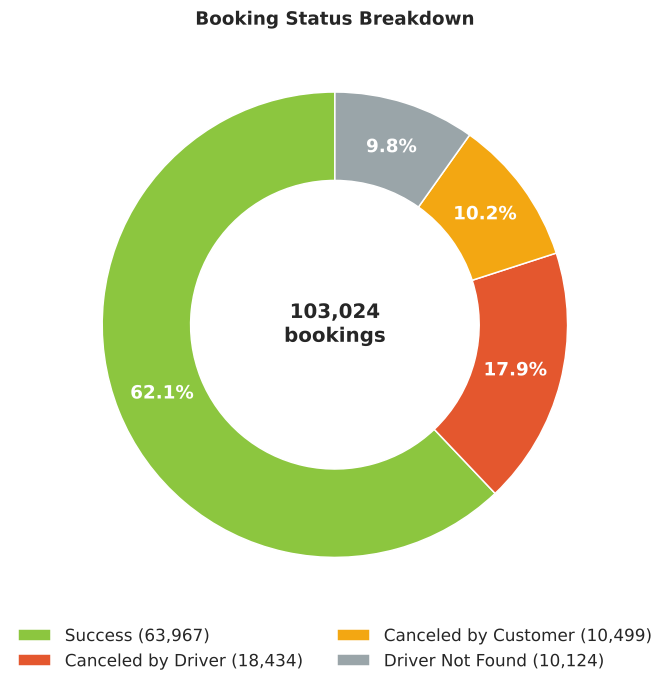

In [13]:
# Chart - 1 visualization code : Booking Status Breakdown (donut)
status = df_clean["Booking_Status"].value_counts()
fig, ax = plt.subplots(figsize=(6.5, 6.5))
wedges, *_ = ax.pie(status, labels=None, autopct="%1.1f%%", pctdistance=0.8, startangle=90,
                    colors=[STATUS_COLORS[s] for s in status.index], wedgeprops=dict(width=0.38, edgecolor="white"),
                    textprops=dict(color="white", fontweight="bold"))
ax.legend(wedges, [f"{s} ({n:,})" for s, n in status.items()], loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
ax.text(0, 0, f"{len(df_clean):,}\nbookings", ha="center", va="center", fontsize=13, fontweight="bold")
ax.set_title("Booking Status Breakdown")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A donut chart shows part-to-whole for a handful of categories at a glance, and the centre can hold the total. Only four statuses exist, so the slices stay readable.

##### 2. What is/are the insight(s) found from the chart?

* **62.1%** of bookings succeed and **37.9%** fail.
* Drivers cancel **17.9%** of bookings, **1.76×** more than customers (10.2%).
* **9.8%** of bookings find no driver at all, which is a pure supply gap.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Every percentage point of fulfilment recovered is ~1,000 extra rides a month. The negative signal is that driver cancellations plus no-driver bookings (27.7%) exceed customer cancellations by almost 3×. Fulfilment is constrained by supply-side behaviour, which hurts customer trust and repeat usage if left unaddressed.

#### Chart - 2 - Ride Volume Over Time

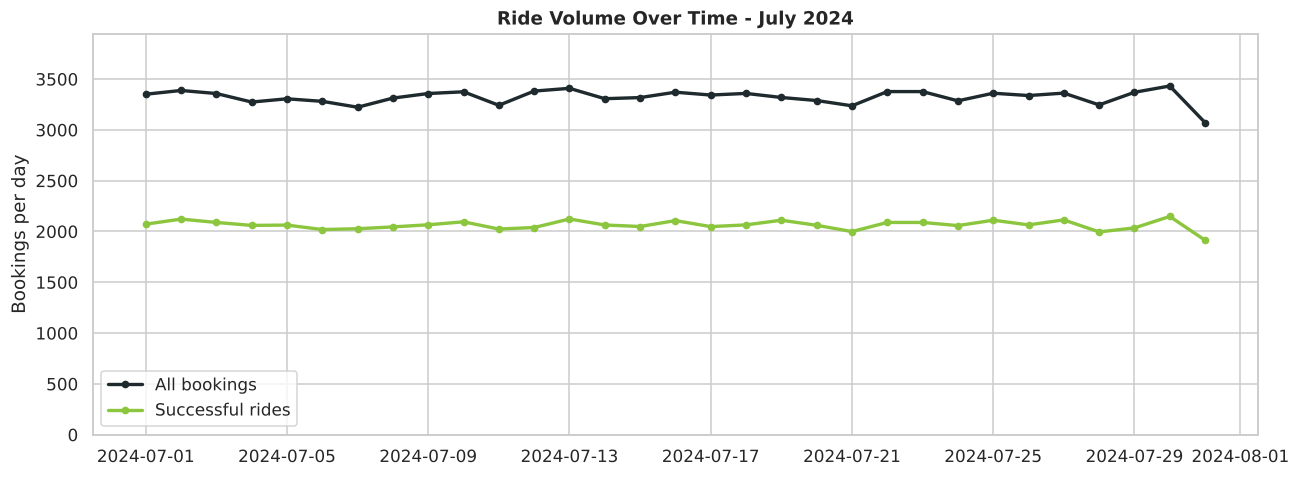

Avg bookings/day: 3323 | Avg successful/day: 2063


In [14]:
# Chart - 2 visualization code : Ride Volume Over Time (daily)
daily = df_clean.groupby(["Booking_Date", "Booking_Status"]).size().unstack(fill_value=0)
daily.index = pd.to_datetime(daily.index)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily.index, daily.sum(axis=1), color=OLA_DARK, lw=2.2, marker="o", ms=4, label="All bookings")
ax.plot(daily.index, daily["Success"], color=OLA_GREEN, lw=2.2, marker="o", ms=4, label="Successful rides")
ax.set_ylim(0, daily.sum(axis=1).max() * 1.15)
ax.set_title("Ride Volume Over Time - July 2024"); ax.set_ylabel("Bookings per day")
ax.legend(); plt.tight_layout(); plt.show()
print("Avg bookings/day:", round(daily.sum(axis=1).mean()), "| Avg successful/day:", round(daily["Success"].mean()))

##### 1. Why did you pick the specific chart?

A line chart is the natural choice for a time series, and plotting total vs successful bookings together shows the fulfilment gap every day.

##### 2. What is/are the insight(s) found from the chart?

* Volume is very stable at **~3,320 bookings/day** (min 3,072 on 31 Jul, max 3,432 on 30 Jul), with ~2,060 successful rides/day.
* There are no weekly spikes or payday effects. The success share holds near 62% every day.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Stable demand makes driver supply planning predictable, so fixed shift-based incentives can be designed with confidence. The negative is that the gap between the lines is constant, which means lost demand is systemic, not a one-off event.

#### Chart - 3 - Peak Demand Hours

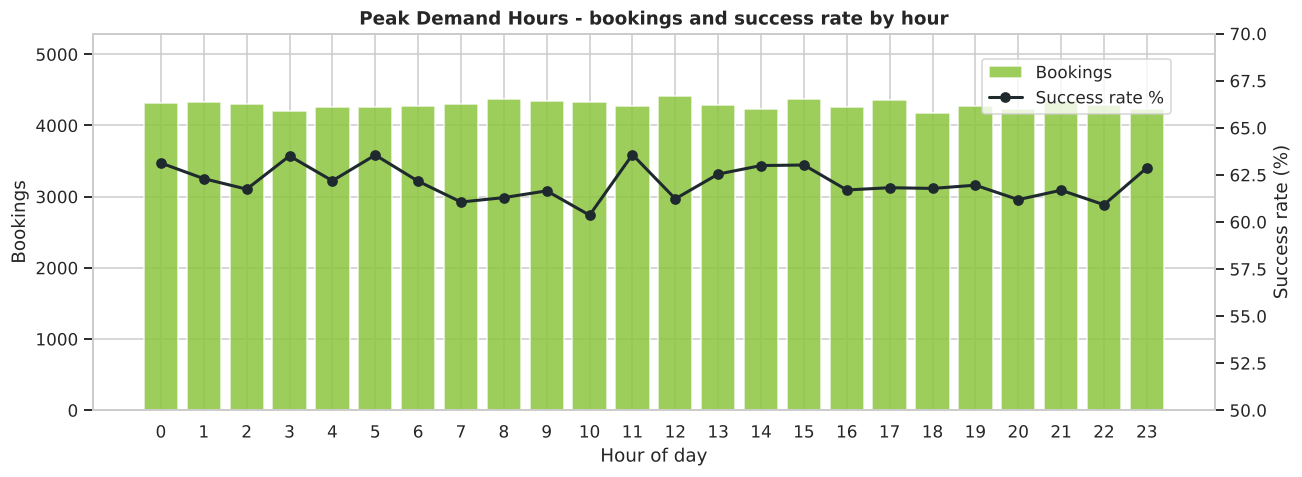

,Bookings,Success_Rate
Hour,,
12,4408,0.612296
15,4376,0.630256
8,4374,0.612940
17,4353,0.618194
9,4347,0.616517


In [15]:
# Chart - 3 visualization code : Bookings by hour with success rate
hourly = df_clean.groupby("Hour").agg(Bookings=("Booking_ID", "size"), Success_Rate=("Is_Success", "mean"))
fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(hourly.index, hourly["Bookings"], color=OLA_GREEN, alpha=0.85, label="Bookings")
ax1.set_xlabel("Hour of day"); ax1.set_ylabel("Bookings"); ax1.set_xticks(range(24))
ax1.set_ylim(0, hourly["Bookings"].max() * 1.2)
ax2 = ax1.twinx()
ax2.plot(hourly.index, hourly["Success_Rate"] * 100, color=OLA_DARK, marker="o", lw=2, label="Success rate %")
ax2.set_ylim(50, 70); ax2.set_ylabel("Success rate (%)"); ax2.grid(False)
ax1.set_title("Peak Demand Hours - bookings and success rate by hour")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88)); plt.tight_layout(); plt.show()
hourly.sort_values("Bookings", ascending=False).head(5)

##### 1. Why did you pick the specific chart?

Bars show volume per hour and the overlaid line shows success rate on a second axis. Together they answer whether peak hours are also the worst-served hours.

##### 2. What is/are the insight(s) found from the chart?

* Demand is almost flat across 24 hours (**~4,200-4,400 per hour**). The busiest hours are 12:00, 15:00 and 08:00, but only by ~2%.
* Success rate stays between **60% and 63%** for every hour, so there is no specific rush-hour breakdown.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: driver allocation does not need sharp peak surges, so a uniform 24×7 supply plan with slight boosts at 08-10, 12 and 15-17 is enough. Negative: since failures are not time-specific, surge pricing alone will not fix fulfilment. The root causes are driver behaviour and coverage, not timing.

#### Chart - 4 - Average Bookings by Weekday

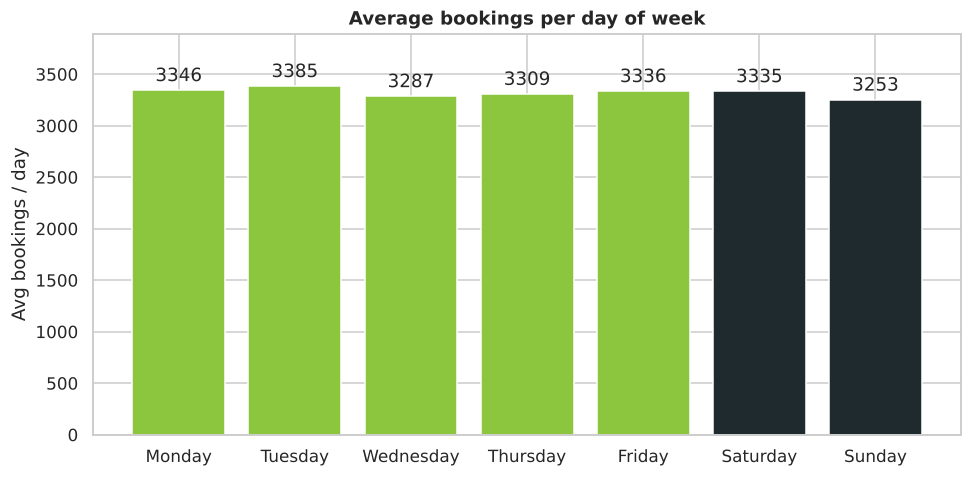

Raw counts are misleading - July 2024 had 5 Mondays, Tuesdays and Wednesdays:
Day_Name
Friday       4
Monday       5
Saturday     4
Sunday       4
Thursday     4
Tuesday      5
Wednesday    5
Name: Booking_Date, dtype: int64


In [16]:
# Chart - 4 visualization code : Average bookings per weekday (normalised by number of such days in July)
days_in_month = df_clean.groupby("Day_Name")["Booking_Date"].nunique()
wk = (df_clean.groupby("Day_Name").size() / days_in_month).reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(wk.index, wk.values, color=[OLA_GREEN if d not in ("Saturday", "Sunday") else OLA_DARK for d in wk.index])
ax.bar_label(bars, fmt="%.0f", padding=3); ax.set_ylim(0, wk.max() * 1.15)
ax.set_title("Average bookings per day of week"); ax.set_ylabel("Avg bookings / day")
plt.tight_layout(); plt.show()
print("Raw counts are misleading - July 2024 had 5 Mondays, Tuesdays and Wednesdays:")
print(days_in_month)

##### 1. Why did you pick the specific chart?

A bar chart compares discrete categories (weekdays). It is **normalised per day** because raw counts are biased by July having five Mon/Tue/Wed.

##### 2. What is/are the insight(s) found from the chart?

* Raw totals suggest Mon-Wed are ~25% busier, but per-day averages are **flat (~3,250-3,390)** across all weekdays and weekends.
* Weekend demand (~3,290/day) is about the same as weekdays (~3,330/day).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This prevents a costly wrong decision (over-staffing Mon-Wed based on raw totals). Weekend demand matching weekdays means there is no weekend dip to fill with promotions. Leisure-focused weekend campaigns could still grow demand on top of the commute base.

#### Chart - 5 - Top 5 Vehicle Types by Ride Distance

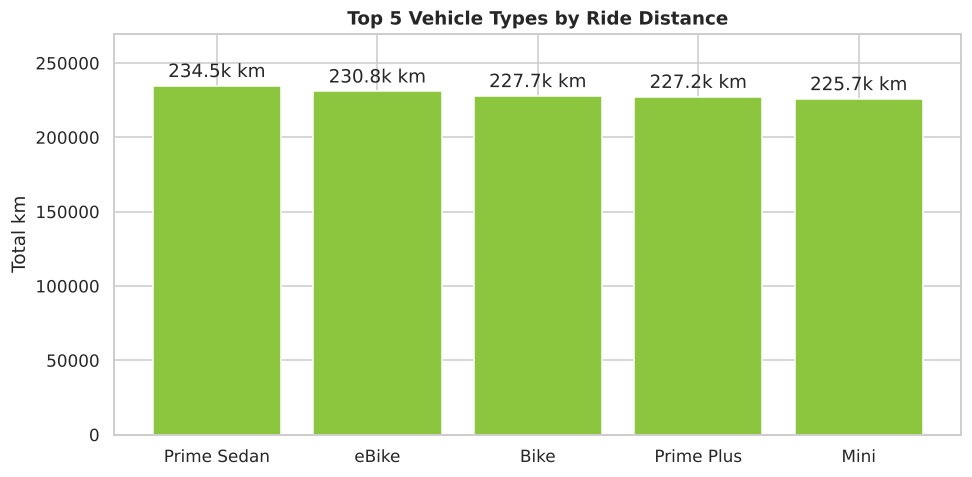

In [17]:
# Chart - 5 visualization code : Top 5 vehicle types by total ride distance (successful rides)
veh_dist = success.groupby("Vehicle_Type")["Ride_Distance"].sum().sort_values(ascending=False).head(5)
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(veh_dist.index, veh_dist.values, color=OLA_GREEN)
ax.bar_label(bars, labels=[f"{v/1000:.1f}k km" for v in veh_dist.values], padding=3)
ax.set_ylim(0, veh_dist.max() * 1.15); ax.set_ylabel("Total km"); ax.set_title("Top 5 Vehicle Types by Ride Distance")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A sorted bar chart is the clearest way to show a top-N ranking, and the brief specifically asks for the top 5 vehicle types by distance.

##### 2. What is/are the insight(s) found from the chart?

* **Prime Sedan (234.5k km)** leads, closely followed by eBike, Bike, Prime Plus and Mini (~226-231k km each).
* Auto falls out of the top 5 with only 92k km because its trips are much shorter (see next chart).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Distance drives fuel, maintenance and driver earnings. Prime Sedan and eBike carry the most kilometres, so fleet maintenance budgets and EV charging partnerships should prioritise them. No negative signal here.

#### Chart - 6 - Average Ride Distance by Vehicle Type

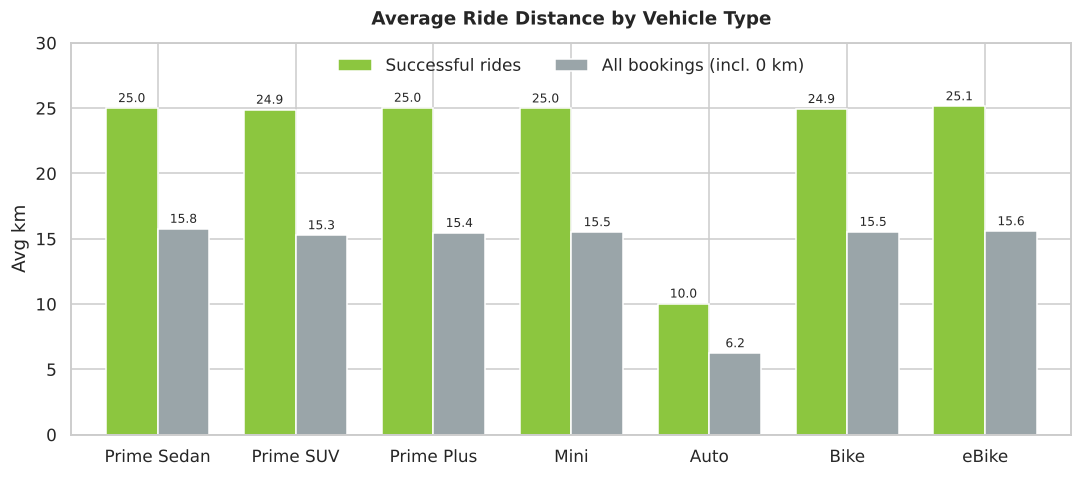

In [18]:
# Chart - 6 visualization code : Average ride distance per vehicle (successful rides) vs all bookings
avg_dist = pd.DataFrame({
    "Successful rides": success.groupby("Vehicle_Type")["Ride_Distance"].mean(),
    "All bookings (incl. 0 km)": df_clean.groupby("Vehicle_Type")["Ride_Distance"].mean(),
}).reindex(VEH_ORDER)
ax = avg_dist.plot(kind="bar", figsize=(10, 4.5), color=[OLA_GREEN, OLA_GREY], width=0.75, rot=0)
for c in ax.containers: ax.bar_label(c, fmt="%.1f", padding=2, fontsize=8)
ax.set_ylim(0, 30); ax.legend(loc="upper center", ncol=2, frameon=False)
ax.set_ylabel("Avg km"); ax.set_xlabel(""); ax.set_title("Average Ride Distance by Vehicle Type", pad=12)
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A grouped bar compares two averages per vehicle side by side. It shows the true trip length and also why the 'all bookings' average (SQL Q2) is lower.

##### 2. What is/are the insight(s) found from the chart?

* Six vehicle types average **~25 km** per completed trip, while **Auto averages only 10 km**.
* Averages over all bookings (~15.5 km, Auto 6.2 km) are diluted by 0-km cancelled bookings, so trip length should be judged on successful rides.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Autos clearly serve short hops, so they can be positioned for last-mile and metro connectivity with flat short-trip fares. The longer-trip categories suit airport and outstation packages. Using the wrong average (incl. 0 km) would understate trip lengths by ~38% and mislead pricing.

#### Chart - 7 - Revenue by Payment Method

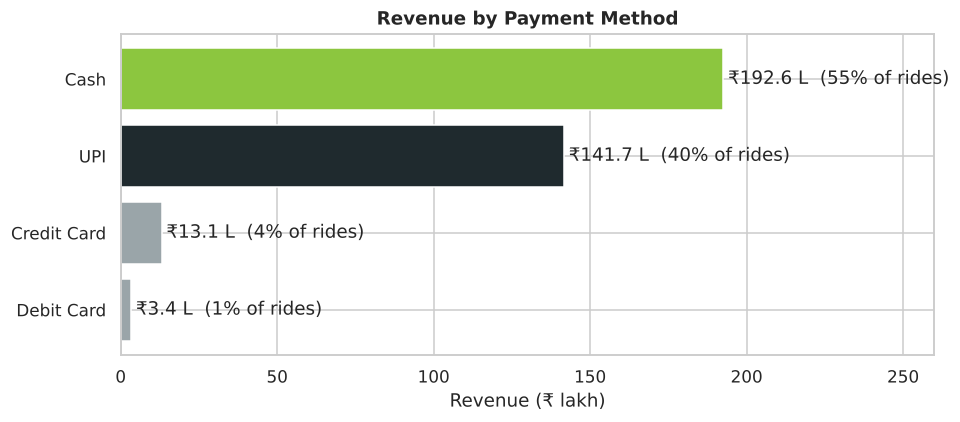

In [19]:
# Chart - 7 visualization code : Revenue by payment method (successful rides)
pay = success.groupby("Payment_Method").agg(Revenue=("Booking_Value", "sum"), Rides=("Booking_ID", "size")).sort_values("Revenue")
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(pay.index, pay["Revenue"] / 1e5, color=[OLA_GREY, OLA_GREY, OLA_DARK, OLA_GREEN])
ax.bar_label(bars, labels=[f"₹{v/1e5:.1f} L  ({r/pay.Rides.sum():.0%} of rides)" for v, r in zip(pay.Revenue, pay.Rides)], padding=3)
ax.set_xlim(0, pay["Revenue"].max() / 1e5 * 1.35); ax.set_xlabel("Revenue (₹ lakh)")
ax.set_title("Revenue by Payment Method"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart ranks the four payment methods clearly and leaves room for revenue and ride-share labels.

##### 2. What is/are the insight(s) found from the chart?

* Total revenue from successful rides is **₹3.51 Cr**.
* **Cash ₹1.93 Cr (55% of rides)** leads, followed by UPI ₹1.42 Cr (40%). Credit cards (₹13 L) and debit cards (₹3.4 L) are marginal.
* The average fare is the same (~₹540-550) across methods.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Cash dependence is a negative signal: it means cash-handling risk, slower settlement and less data on customers. Shifting even 10% of cash rides to UPI through cashback would speed up collections and enable personalised marketing. Card usage is tiny, so card-linked offers have limited reach.

#### Chart - 8 - Top 5 Customers by Total Booking Value

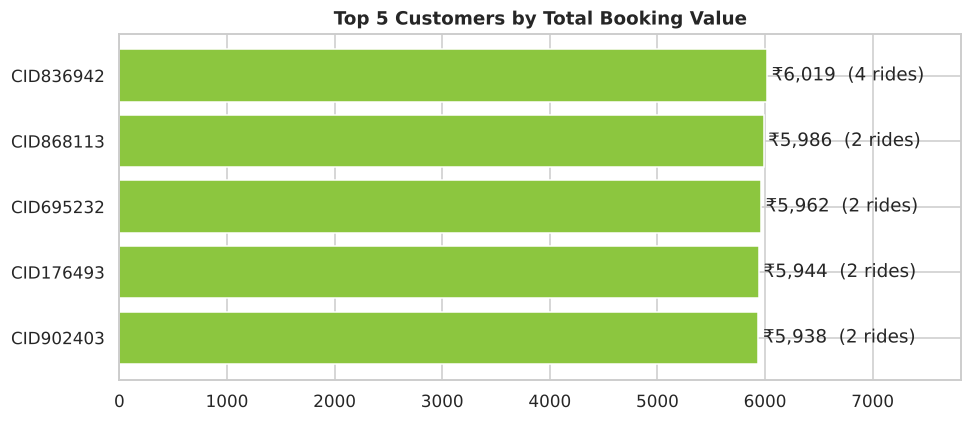

In [20]:
# Chart - 8 visualization code : Top 5 customers by total booking value (successful rides)
top_cust = success.groupby("Customer_ID").agg(Value=("Booking_Value", "sum"), Rides=("Booking_ID", "size")).nlargest(5, "Value")
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(top_cust.index[::-1], top_cust["Value"][::-1], color=OLA_GREEN)
ax.bar_label(bars, labels=[f"₹{v:,}  ({r} rides)" for v, r in zip(top_cust.Value[::-1], top_cust.Rides[::-1])], padding=3)
ax.set_xlim(0, top_cust["Value"].max() * 1.3); ax.set_title("Top 5 Customers by Total Booking Value")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A ranked horizontal bar suits a top-N list with long IDs as labels.

##### 2. What is/are the insight(s) found from the chart?

* The top customer **CID836942 spent ₹6,019 over 4 rides**. The rest are ~₹5,940-5,990, mostly from just **2 rides**, which points to high-fare premium trips rather than frequency.
* The customer base is extremely fragmented: 91.6% of customers booked only once in July.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

High-value customers are identifiable and can be targeted with premium loyalty perks. The negative insight is very low repeat usage (only 8.4% booked twice or more), which signals weak retention. A loyalty or subscription programme is a clear growth opportunity.

#### Chart - 9 - Ride Distance Distribution Per Day

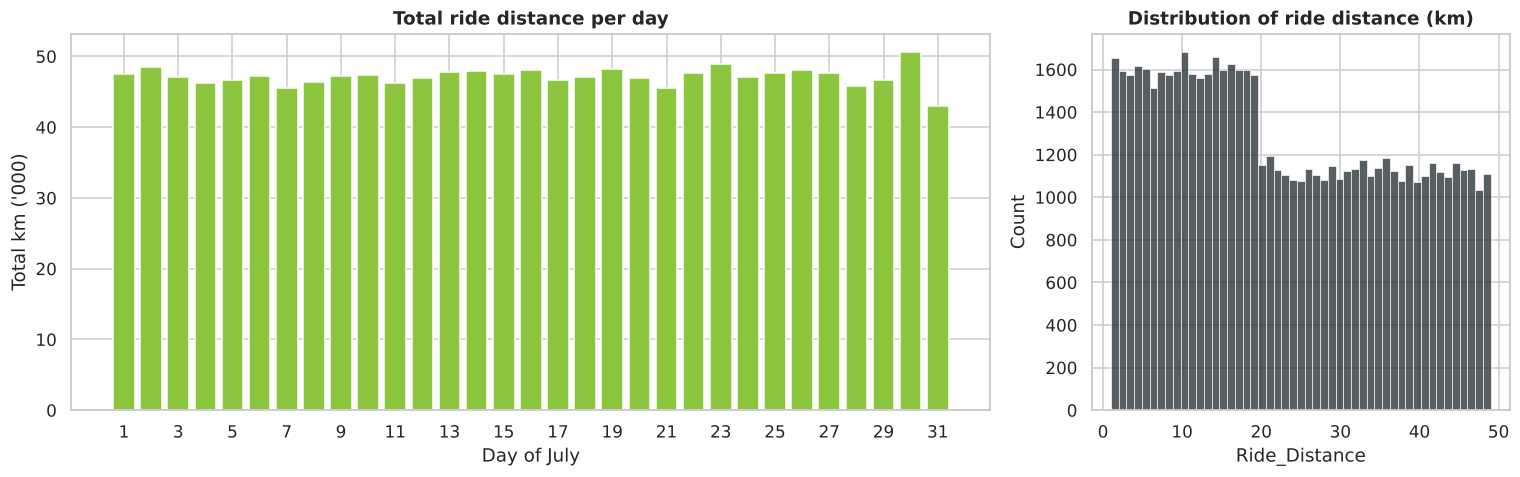

In [21]:
# Chart - 9 visualization code : Ride distance distribution per day
day_dist = success.groupby("Day")["Ride_Distance"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].bar(day_dist.sum().index, day_dist.sum().values / 1000, color=OLA_GREEN)
axes[0].set_xlabel("Day of July"); axes[0].set_ylabel("Total km ('000)"); axes[0].set_title("Total ride distance per day")
axes[0].set_xticks(range(1, 32, 2))
sns.histplot(success["Ride_Distance"], bins=49, color=OLA_DARK, ax=axes[1])
axes[1].set_title("Distribution of ride distance (km)")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The left bar chart shows how much distance is covered each day, and the histogram on the right shows the shape of individual trip lengths.

##### 2. What is/are the insight(s) found from the chart?

* Daily distance is steady at **~47k km/day** (43k-51k range).
* Trip lengths run from 1 to 49 km. They are roughly uniform from 1-49 km, with an extra hump at short distances from Autos.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Predictable daily kilometres help forecast fuel and EV-charging demand and driver earnings. No negative signal. The wide spread of trip lengths supports both short-hop and long-trip product lines.

#### Chart - 10 - Cancelled Rides Reasons - Customer

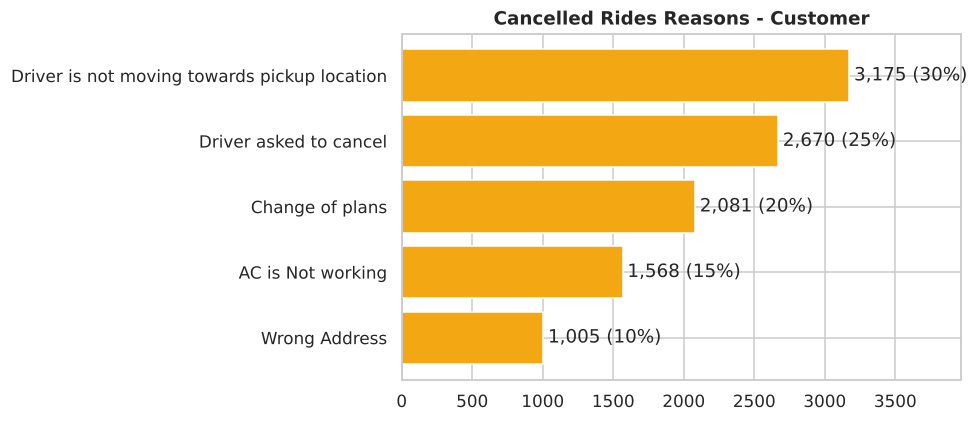

In [22]:
# Chart - 10 visualization code : Customer cancellation reasons
cust_reason = df_clean.loc[df_clean["Booking_Status"] == "Canceled by Customer", "Canceled_Rides_by_Customer"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(cust_reason.index, cust_reason.values, color="#F3A712")
ax.bar_label(bars, labels=[f"{v:,} ({v/cust_reason.sum():.0%})" for v in cust_reason.values], padding=3)
ax.set_xlim(0, cust_reason.max() * 1.25); ax.set_title("Cancelled Rides Reasons - Customer")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Horizontal bars rank reasons with long text labels cleanly, and percentages show each reason's share.

##### 2. What is/are the insight(s) found from the chart?

* **Driver not moving towards pickup (30%)** and **Driver asked to cancel (25%)** account for 55% of customer cancellations. Both are driver behaviour issues.
* Change of plans (20%), AC not working (15%) and Wrong address (10%) make up the rest.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Over half of 'customer' cancellations are actually driver-caused. Live GPS checks (auto-reassign if the driver is not moving) and penalties for drivers who ask customers to cancel could recover ~5,800 rides a month. 'AC not working' is a fleet-quality issue worth a vehicle-inspection check.

#### Chart - 11 - Cancelled Rides Reasons - Driver

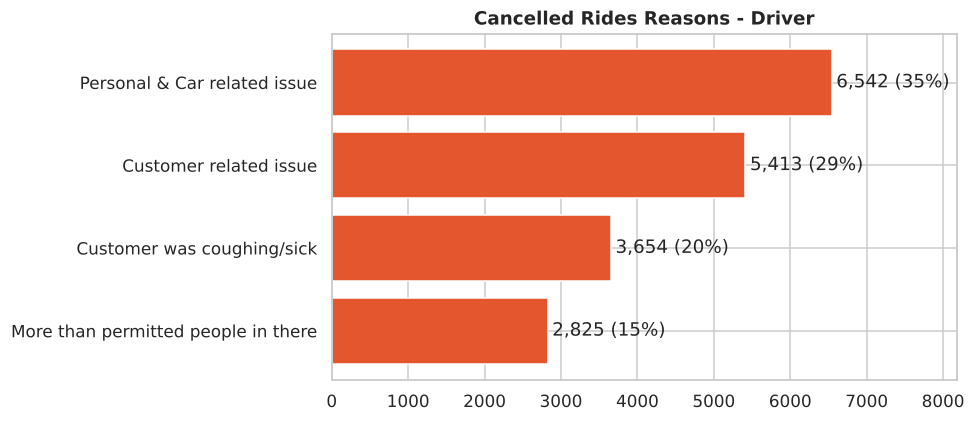

In [23]:
# Chart - 11 visualization code : Driver cancellation reasons
drv_reason = df_clean.loc[df_clean["Booking_Status"] == "Canceled by Driver", "Canceled_Rides_by_Driver"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(drv_reason.index, drv_reason.values, color="#E4572E")
ax.bar_label(bars, labels=[f"{v:,} ({v/drv_reason.sum():.0%})" for v in drv_reason.values], padding=3)
ax.set_xlim(0, drv_reason.max() * 1.25); ax.set_title("Cancelled Rides Reasons - Driver")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Same as above. Ranked horizontal bars keep the two cancellation views consistent and easy to compare.

##### 2. What is/are the insight(s) found from the chart?

* **Personal & car related issue (35%)** is the top driver reason, followed by customer related issue (29%), customer coughing/sick (20%) and more than permitted people (15%).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Personal and car issues point to drivers accepting rides they cannot fulfil. Letting drivers go 'offline' easily and doing preventive maintenance would cut these. The negative signal is that 'customer related' reasons are vague and unverifiable, so stricter reason capture is needed to stop drivers using them as easy excuses.

#### Chart - 12 - Driver Ratings Distribution

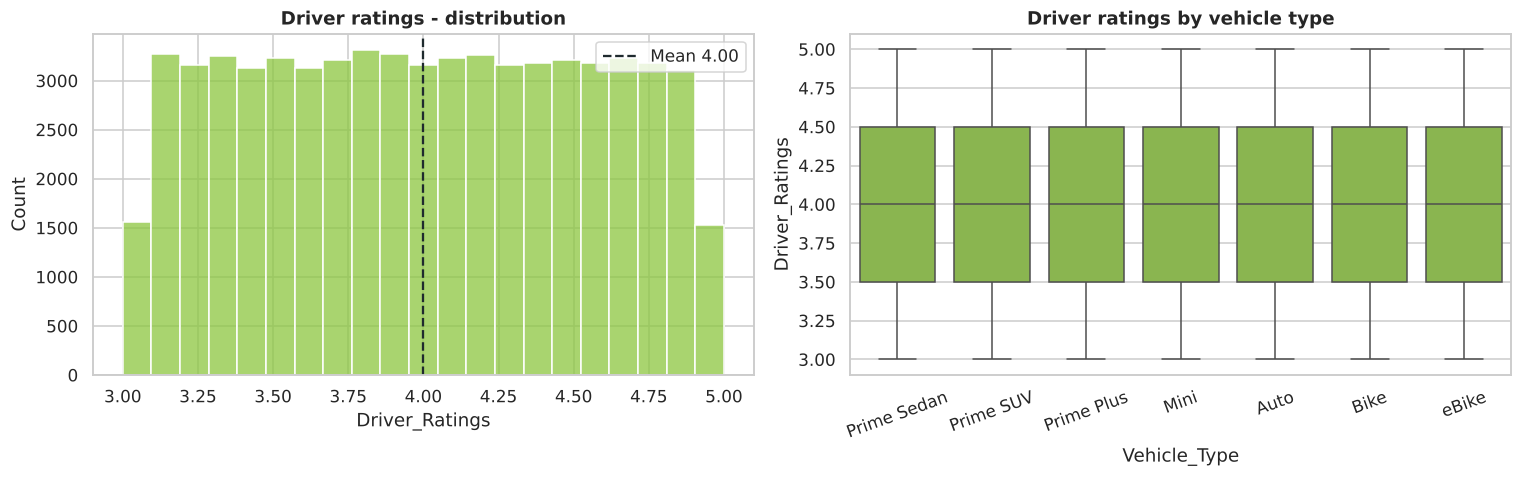

In [24]:
# Chart - 12 visualization code : Driver ratings distribution (overall + by vehicle)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(success["Driver_Ratings"], bins=21, color=OLA_GREEN, ax=axes[0])
axes[0].axvline(success["Driver_Ratings"].mean(), color=OLA_DARK, ls="--", label=f"Mean {success['Driver_Ratings'].mean():.2f}")
axes[0].legend(); axes[0].set_title("Driver ratings - distribution")
sns.boxplot(data=success, x="Vehicle_Type", y="Driver_Ratings", order=VEH_ORDER, color=OLA_GREEN, ax=axes[1])
axes[1].set_title("Driver ratings by vehicle type"); axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The histogram shows the shape of the rating distribution, and the box plot compares spread and median across vehicle types in one view.

##### 2. What is/are the insight(s) found from the chart?

* Driver ratings range **3.0-5.0** with a mean of **3.99**, spread almost uniformly. There is no strong clustering at 5 stars.
* Medians and spread are identical across all vehicle types.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: no vehicle category has a service-quality problem. Negative: ~27% of rides are rated 3.5 or below, so a large share of trips are only 'average'. Targeted coaching for consistently low-rated drivers and rewards for 4.5+ drivers can lift the experience.

#### Chart - 13 - Customer vs Driver Ratings

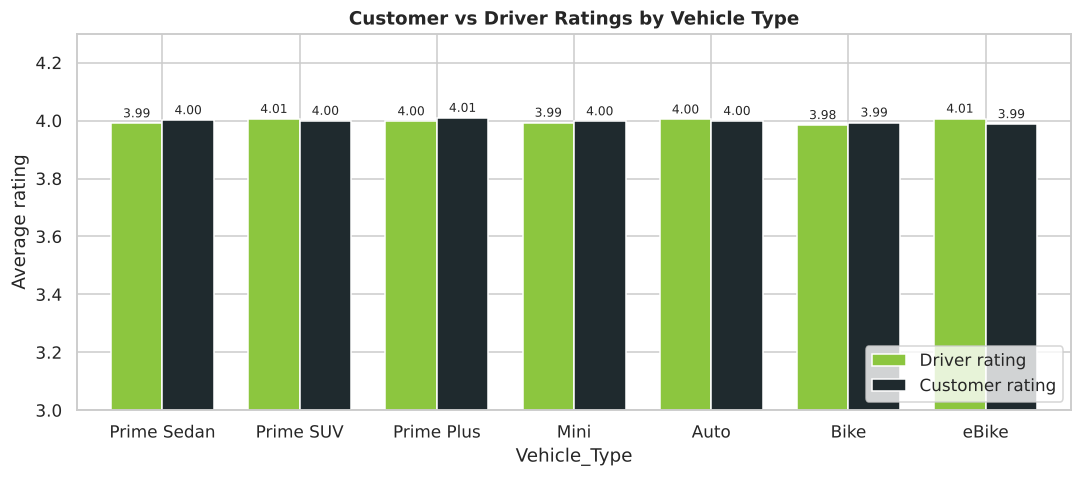

Correlation between driver and customer rating per ride: -0.003


In [25]:
# Chart - 13 visualization code : Customer vs driver ratings by vehicle type
rat = success.groupby("Vehicle_Type")[["Driver_Ratings", "Customer_Rating"]].mean().reindex(VEH_ORDER)
ax = rat.plot(kind="bar", figsize=(10, 4.5), color=[OLA_GREEN, OLA_DARK], width=0.75, rot=0)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", padding=2, fontsize=8)
ax.set_ylim(3, 4.3); ax.set_ylabel("Average rating"); ax.set_title("Customer vs Driver Ratings by Vehicle Type")
ax.legend(["Driver rating", "Customer rating"], loc="lower right")
plt.tight_layout(); plt.show()
print("Correlation between driver and customer rating per ride:",
      round(success[["Driver_Ratings", "Customer_Rating"]].corr().iloc[0, 1], 3))

##### 1. Why did you pick the specific chart?

A grouped bar puts both rating sides next to each other per vehicle. The y-axis starts at 3 (the minimum possible rating) to make small gaps visible.

##### 2. What is/are the insight(s) found from the chart?

* Both sides average **~4.0** for every vehicle type. Prime Plus customers rate slightly highest (4.01) and Bike/eBike slightly lowest (3.99).
* Per ride, driver and customer ratings are uncorrelated (r ≈ 0): a good driver rating does not imply a good customer rating.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Balanced ratings show no systemic conflict between drivers and riders. However, because the ratings do not differentiate anything, the rating system is not very informative. Adding tags (cleanliness, driving, punctuality) would make feedback actionable.

#### Chart - 14 - Correlation Heatmap

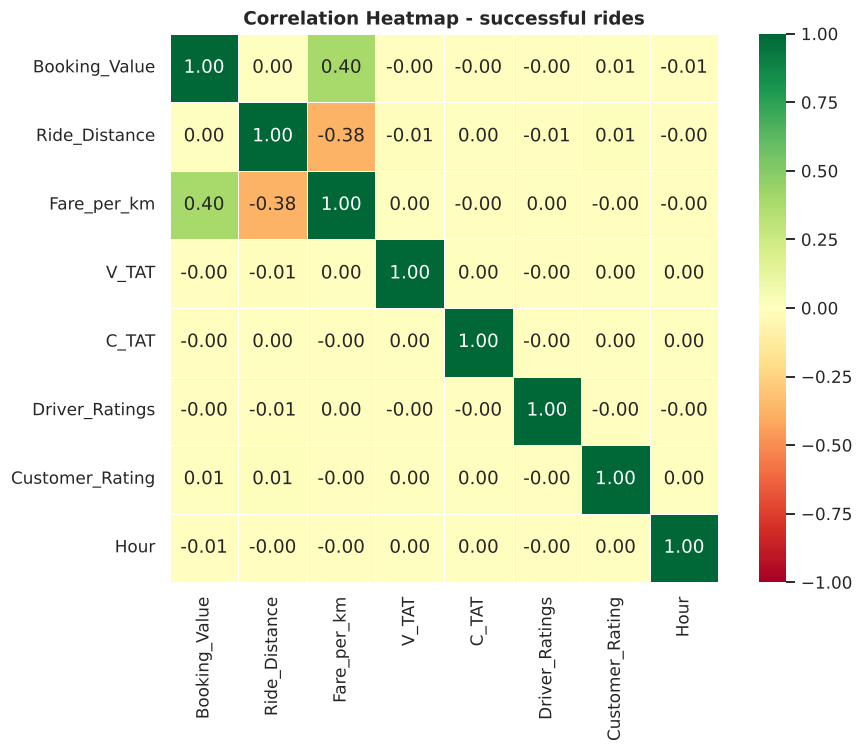

In [26]:
# Correlation Heatmap visualization code (successful rides - numeric fields)
num_cols = ["Booking_Value", "Ride_Distance", "Fare_per_km", "V_TAT", "C_TAT", "Driver_Ratings", "Customer_Rating", "Hour"]
corr = success[num_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation Heatmap - successful rides"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A heatmap of the correlation matrix shows every pairwise linear relationship between numeric variables in one compact view.

##### 2. What is/are the insight(s) found from the chart?

* **Booking_Value vs Ride_Distance ≈ 0.00**: fares are not driven by distance in this data, which is a pricing anomaly. Fare_per_km correlates with value (+0.40) and inversely with distance (-0.38) only because it is derived from them.
* TAT, ratings and hour show **no relationship** with fare or each other.
* Implication: the pricing logic (surge, minimum fares) should be audited. Short trips with very high fares (top 1% above ₹640/km against a ₹20/km median) are candidates for fraud or pricing-error review.

#### Chart - 15 - Pair Plot

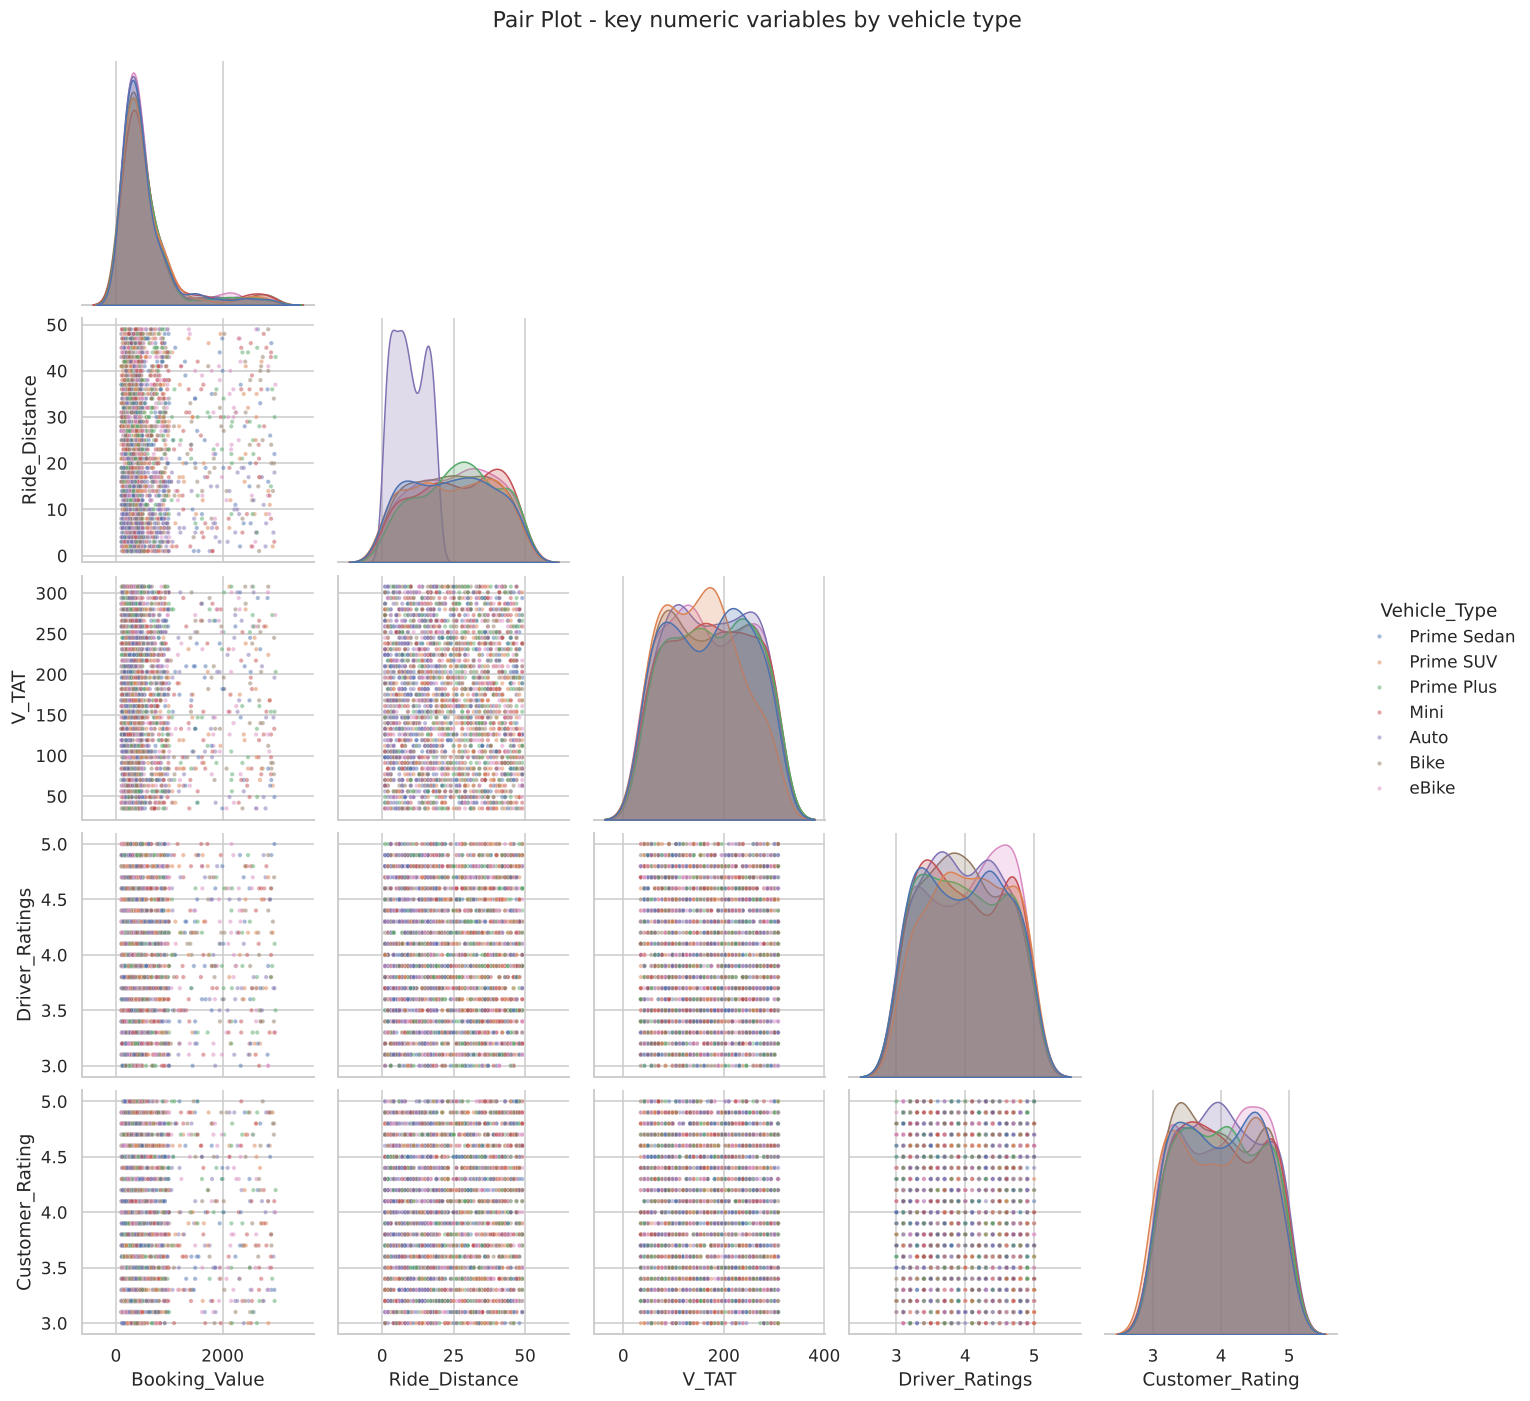

In [27]:
# Pair Plot visualization code (sample of 3,000 successful rides to keep it fast)
sample = success.sample(3000, random_state=42)
g = sns.pairplot(sample, vars=["Booking_Value", "Ride_Distance", "V_TAT", "Driver_Ratings", "Customer_Rating"],
                 hue="Vehicle_Type", hue_order=VEH_ORDER, corner=True, plot_kws=dict(s=8, alpha=0.5), diag_kind="kde")
g.fig.suptitle("Pair Plot - key numeric variables by vehicle type", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows the distribution of each variable and the scatter of every pair, coloured by vehicle type. It helps spot clusters or segments a correlation number would miss.

##### 2. What is/are the insight(s) found from the chart?

* Scatter clouds are uniform squares with no trends, which confirms the near-zero correlations.
* **Auto** separates clearly on Ride_Distance (capped at ~20 km) while other vehicles span 1-49 km.
* Ratings sit on a discrete 0.1 grid between 3 and 5 for every vehicle type. There are no low-rating outliers (nothing below 3).

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

1. **Fix driver-side cancellations (biggest lever).** Penalise drivers who cancel or ask customers to cancel, and auto-reassign when GPS shows the driver is not moving. This targets ~24k of the ~39k lost bookings.
2. **Close supply gaps.** Use "Driver Not Found" locations and hours to rebalance idle drivers and give acceptance bonuses there (~10k lost bookings a month).
3. **Steady 24×7 supply plan.** Demand is flat by hour and weekday, so use fixed shift incentives with small boosts at 08-10, 12 and 15-17 instead of heavy surge reliance.
4. **Go digital.** Shift cash (55%) to UPI with cashback and wallet offers to speed up settlement and capture customer data for personalised marketing.
5. **Retention.** 91.6% of customers rode once. Launch a loyalty or subscription pass and premium perks for high-value customers.
6. **Pricing audit and fraud flags.** Fare does not follow distance, so review the pricing logic and auto-flag rides above ₹640/km.
7. **Richer ratings.** Add feedback tags and coach drivers rated 3.5 or below. Position Autos for short last-mile trips.

# **Conclusion**

* The July 2024 Bengaluru dataset (103k bookings) was cleaned with structural nulls handled correctly and 14 analysis features derived. It now feeds the SQL queries, the Power BI dashboard and the Streamlit app.
* **Fulfilment is the core problem:** 62% success, with driver cancellations (17.9%) and no-driver bookings (9.8%) making up most of the loss, about ₹2.15 Cr of quoted value in one month.
* Demand is remarkably stable by day, hour and weekday, so the issues are **structural (driver behaviour, supply, pricing)** rather than peak-time capacity.
* Revenue of ₹3.51 Cr is cash-heavy, customers rarely repeat, ratings are uniform around 4.0 and fares do not track distance. Each of these is a concrete action area: digital payments, loyalty, feedback quality and a pricing audit.
* Acting on driver cancellations alone could lift completed rides by double digits without any growth in demand.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***